# 10. Graph machine learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/10_ml.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/10_ml.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You make the road graph of Monaco as a PyTorch Geometric graph, in two forms, and train a small graph neural network on it. The module is `duckosm.ml`. [duckOSM for graph machine learning users](https://khoshkhah.github.io/duckOSM/compare/for-ml-users/) has the details and an example with city2graph.

| Graph | A node is | An arc is |
|---|---|---|
| `graph="nodes"` | a junction (`lon`, `lat`) | an edge, with the edge features |
| `graph="turns"` | an edge, with the edge features | a legal turn (`cost`, the seconds of the first edge) |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:                       # duckosm is there: no install
    import duckosm         # the SDK
except ImportError:        # else install it with the extras of this notebook (Colab has torch)
    %pip install -q "duckosm[ml,viz]"
    import duckosm         # the SDK
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving"], name="monaco")    # get and build the driving network of Monaco
net                                                   # the card

cut: 34794 nodes, 5693 ways, 343 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5


## The junction graph

A text column (`highway`) becomes one 0/1 column for each value. `edge_id` is a tensor with the `edge_id` of each arc, so each prediction goes back to its edge.

In [3]:
data = duckosm.ml.to_pyg(net.driving, features=["length_m", "maxspeed_kmh", "lanes", "highway"])    # the junction graph
data                                                                                                 # its tensors

Data(x=[1768, 2], edge_index=[2, 2840], edge_attr=[2840, 13], num_nodes=1768, edge_id=[2840], node_id=[1768], x_names=[2], edge_attr_names=[13])

In [4]:
data.edge_attr_names[:6], data.edge_id[:3]    # the first feature columns, and the first edge ids

(['length_m',
  'maxspeed_kmh',
  'lanes',
  'highway=living_street',
  'highway=primary',
  'highway=primary_link'],
 tensor([  414242052250797,  2214154189574909, 15757195119014288]))

## The turn graph, and a model

On the turn graph each node is an edge. The model learns the speed limit of an edge from its length, its lanes, its road class and the edges that it connects to. It trains on 80 % of the edges and is checked on the other 20 %.

In [5]:
import torch                                                                    # PyTorch
from torch_geometric.nn import GCNConv                                          # a graph convolution

turns = duckosm.ml.to_pyg(net.driving, graph="turns", features=["length_m", "lanes", "highway"])   # the turn graph
speed = torch.tensor(net.sql("SELECT maxspeed_kmh FROM driving.edges ORDER BY edge_id").maxspeed_kmh.to_numpy(),
                     dtype=torch.float32)                                       # the target, in the order of the nodes
x = (turns.x - turns.x.mean(0)) / (turns.x.std(0) + 1e-6)                       # the features, scaled
test = torch.rand(turns.num_nodes, generator=torch.Generator().manual_seed(0)) < 0.2    # 20 % of the edges to check
turns

Data(x=[2840, 12], edge_index=[2, 5082], edge_attr=[5082, 1], num_nodes=2840, edge_id=[2840], x_names=[12], edge_attr_names=[1])

In [6]:
class Model(torch.nn.Module):                                                   # two graph convolutions and a line
    def __init__(self, n):
        super().__init__()
        self.a, self.b, self.out = GCNConv(n, 32), GCNConv(32, 32), torch.nn.Linear(32, 1)

    def forward(self, x, edge_index):
        x = torch.relu(self.a(x, edge_index))                                   # the edge and its neighbours
        x = torch.relu(self.b(x, edge_index))                                   # and their neighbours
        return self.out(x).squeeze(-1)                                          # the speed

torch.manual_seed(0)                                                            # the same result at each run
model = Model(x.shape[1])
opt = torch.optim.Adam(model.parameters(), lr=0.01)
for epoch in range(300):                                                        # train on the 80 %
    opt.zero_grad()
    loss = torch.nn.functional.l1_loss(model(x, turns.edge_index)[~test], speed[~test])
    loss.backward()
    opt.step()
predicted = model(x, turns.edge_index).detach()                                 # the speed of each edge
{"error of the model (km/h)": round(float((predicted - speed)[test].abs().mean()), 1),
 "error of the mean speed (km/h)": round(float((speed[~test].mean() - speed[test]).abs().mean()), 1)}    # on the 20 %

{'error of the model (km/h)': 5.6, 'error of the mean speed (km/h)': 13.2}

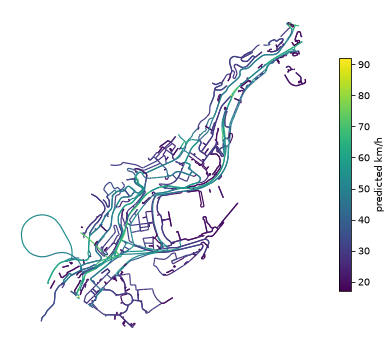

In [7]:
import pandas as pd                                                             # to key the result by edge_id

net.driving.map(color_by=pd.Series(predicted.numpy(), index=turns.edge_id.numpy(), name="predicted km/h"))    # the map